In [ ]:
#environment smoke test — hasasia X.X on Python 3.10, Windows on 31 july

In [1]:
import sys
print(sys.executable)

C:\Anaonda3\envs\pta_sens\python.exe


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import hasasia
print("hasasia version:", hasasia.__version__)

hasasia version: 1.2.3


In [3]:
from hasasia.sim import sim_pta
from hasasia.sensitivity import GWBSensitivityCurve, Spectrum

# 10 fake pulsars, 15-year timespan, ~biweekly cadence, 100 ns timing noise
phi   = np.random.uniform(0, 2*np.pi, 10)
theta = np.random.uniform(0, np.pi, 10)

psrs = sim_pta(timespan=15, cad=20, sigma=1e-7, phi=phi, theta=theta)

freqs = np.logspace(-9, -7, 100)
spectra = [Spectrum(p, freqs=freqs) for p in psrs]
for s in spectra:
    s.NcalInv   # forces the internal noise computation

sc = GWBSensitivityCurve(spectra)
print("built OK, curve has", len(sc.freqs), "frequency points")

built OK, curve has 100 frequency points


findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


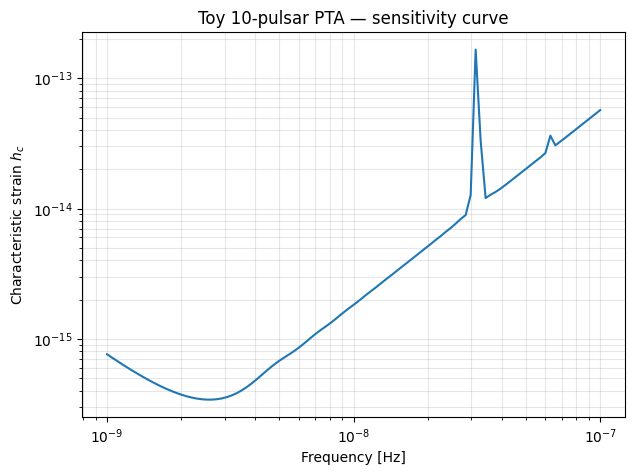

In [4]:
plt.figure(figsize=(7,5))
plt.loglog(sc.freqs, sc.h_c)
plt.xlabel('Frequency [Hz]')
plt.ylabel('Characteristic strain $h_c$')
plt.title('Toy 10-pulsar PTA — sensitivity curve')
plt.grid(True, which='both', alpha=0.3)
plt.show()